# Lecture 2 — Class Exercise
# Bar Charts: World Happiness Report 2023

---

> **Your task:** Create **2 polished bar charts** using the World Happiness Report dataset.  
> **Push to:** `week02/lecture02_exercise.ipynb` in **your own GitHub repo** before the end of class.

---

### Rules to keep in mind 💡
1. Every bar chart **must have a zero baseline** — no exceptions
2. Every chart **must have an insight title**, not a topic title
3. Aim for **professional quality** — clean background, readable font, no clutter
4. Horizontal bars for long category names

---


## Setup — Run this cell first


In [2]:
import pandas as pd
import numpy as np

# World Happiness Report 2023 — representative data
# Source: https://www.kaggle.com/datasets/ajaypalsinghlo/world-happiness-report-2023

df = pd.read_csv('world_happiness_2023.csv')
df.columns = ['Country','Region','Happiness_Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']


print(f"Dataset: {len(df)} countries, {len(df.columns)} columns")
print(df.head())


Dataset: 63 countries, 9 columns
       Country                        Region  Happiness_Score     GDP  \
0      Finland                Western Europe            7.804  10.775   
1      Denmark                Western Europe            7.586  10.933   
2      Iceland                Western Europe            7.525  10.878   
3       Israel  Middle East and North Africa            7.473  10.527   
4  Netherlands                Western Europe            7.464  11.015   

   Social_Support  Life_Expectancy  Freedom  Generosity  Corruption  
0           0.954             71.9    0.949       0.142       0.179  
1           0.954             72.7    0.931       0.168       0.234  
2           0.983             72.5    0.961       0.260       0.150  
3           0.916             72.4    0.903       0.149       0.826  
4           0.939             72.4    0.879       0.240       0.296  


In [3]:
import plotly.express as px
import plotly.graph_objects as go

# Explore the dataset before you start
print("Regions in dataset:")
print(df['Region'].value_counts())
print("\nScore range:", df['Happiness_Score'].min(), "–", df['Happiness_Score'].max())
print("\nBottom 10 countries:")
print(df.nsmallest(10, 'Happiness_Score')[['Country','Region','Happiness_Score']])


Regions in dataset:
Region
Western Europe                  15
Latin America and Caribbean     13
Central and Eastern Europe       7
Sub-Saharan Africa               7
Middle East and North Africa     6
North America and ANZ            4
Southeast Asia                   4
South Asia                       4
East Asia                        3
Name: count, dtype: int64

Score range: 1.859 – 7.804

Bottom 10 countries:
        Country                        Region  Happiness_Score
60  Afghanistan                    South Asia            1.859
61      Lebanon  Middle East and North Africa            2.392
62     Zimbabwe            Sub-Saharan Africa            2.995
52     Ethiopia            Sub-Saharan Africa            3.564
53     Tanzania            Sub-Saharan Africa            3.698
48   Bangladesh                    South Asia            3.892
47        India                    South Asia            4.036
50        Kenya            Sub-Saharan Africa            4.112
54       Uganda

---
## Task 1 — Regional Comparison Bar Chart

**What to build:** A horizontal bar chart showing the **average happiness score by region**, sorted from highest to lowest.

**Requirements:**
- Horizontal orientation (category names are long)
- Sorted by score, descending (so the happiest region is at the top)
- Zero baseline on x-axis
- At least one design choice that goes beyond the Plotly default (colour, annotation, labels, etc.)
- An insight title that answers: *which region stands out and why does it matter?*

**Hint:** Use `df.groupby('Region')['Happiness_Score'].mean()` to compute the averages.


                         Region  Happiness_Score
5                    South Asia         3.618250
7            Sub-Saharan Africa         4.064714
3  Middle East and North Africa         4.943333
6                Southeast Asia         5.695250
2   Latin America and Caribbean         5.699000
1                     East Asia         5.966000
0    Central and Eastern Europe         6.338143
4         North America and ANZ         7.018250
8                Western Europe         7.085533


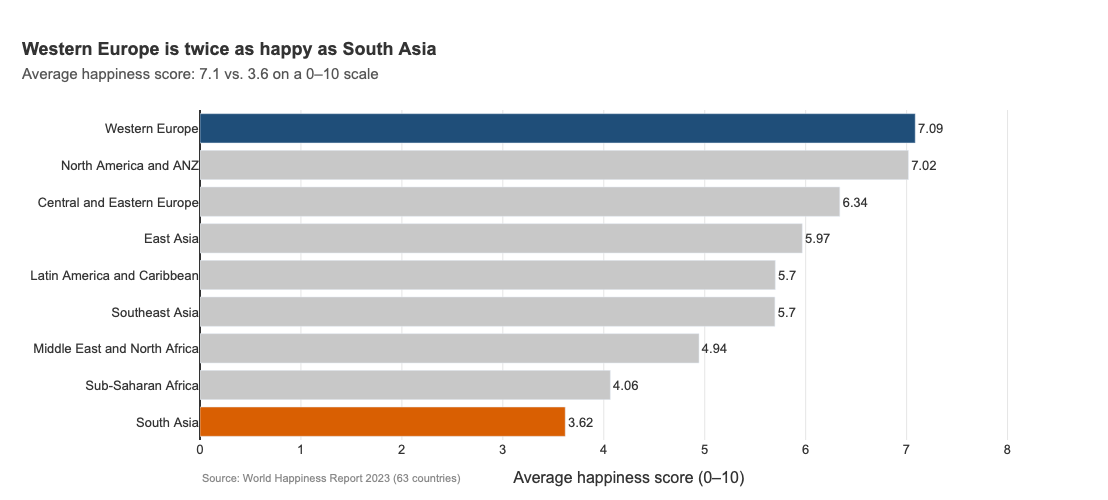

In [6]:
# Task 1: Regional comparison bar chart
# -------------------------------------

# Step 1: Compute average happiness score by region
region_avg = (df.groupby('Region')['Happiness_Score']
              .mean()
              .reset_index()
              .sort_values('Happiness_Score'))  # sort for horizontal bar

print(region_avg)

# Step 2: Build your chart
# YOUR CODE HERE

top_region = region_avg.iloc[-1]['Region']
bottom_region = region_avg.iloc[0]['Region']
colors = ['#1f4e79' if r == top_region else '#d95f02' if r == bottom_region else '#c8c8c8'
          for r in region_avg['Region']]

fig = go.Figure(go.Bar(
    x=region_avg['Happiness_Score'], y=region_avg['Region'], orientation='h',
    marker_color=colors,
    text=region_avg['Happiness_Score'].round(2), textposition='outside',
    cliponaxis=False))

fig.update_layout(
    title=dict(text='<b>Western Europe is twice as happy as South Asia</b><br>'
                    '<span style="font-size:15px;color:#555">Average happiness score: '
                    '7.1 vs. 3.6 on a 0–10 scale</span>',
               x=0.02, xanchor='left'),
    xaxis=dict(range=[0, 8.5], title='Average happiness score (0–10)',
               gridcolor='#e6e6e6', zeroline=True, zerolinecolor='#333'),
    yaxis=dict(title=None),
    plot_bgcolor='white', paper_bgcolor='white',
    font=dict(family='Arial', size=13, color='#333'),
    margin=dict(t=110, l=200, r=50, b=60),
    height=500, width=900, showlegend=False)

fig.add_annotation(
    text='Source: World Happiness Report 2023 (63 countries)',
    xref='paper', yref='paper', x=0, y=-0.14, showarrow=False,
    font=dict(size=11, color='#888'))

fig.show()



---
## Task 2 — Bottom vs. Top: A Contrast Story

**What to build:** A bar chart that highlights the **gap between the happiest and least happy countries**, focusing on a specific insight.

**Requirements:**
- Show the **top 8 AND bottom 8 countries** together (16 bars total)
- Use **colour** to distinguish the two groups (not Plotly's default rainbow)
- Add a **visual separator or annotation** that emphasises the gap
- Insight title that tells the story of the gap

**Hint:** Use `pd.concat([df.nlargest(8,'Happiness_Score'), df.nsmallest(8,'Happiness_Score')])` to get both groups.

**Stretch goal:** Add a vertical reference line showing the global average.


Global average: 5.81


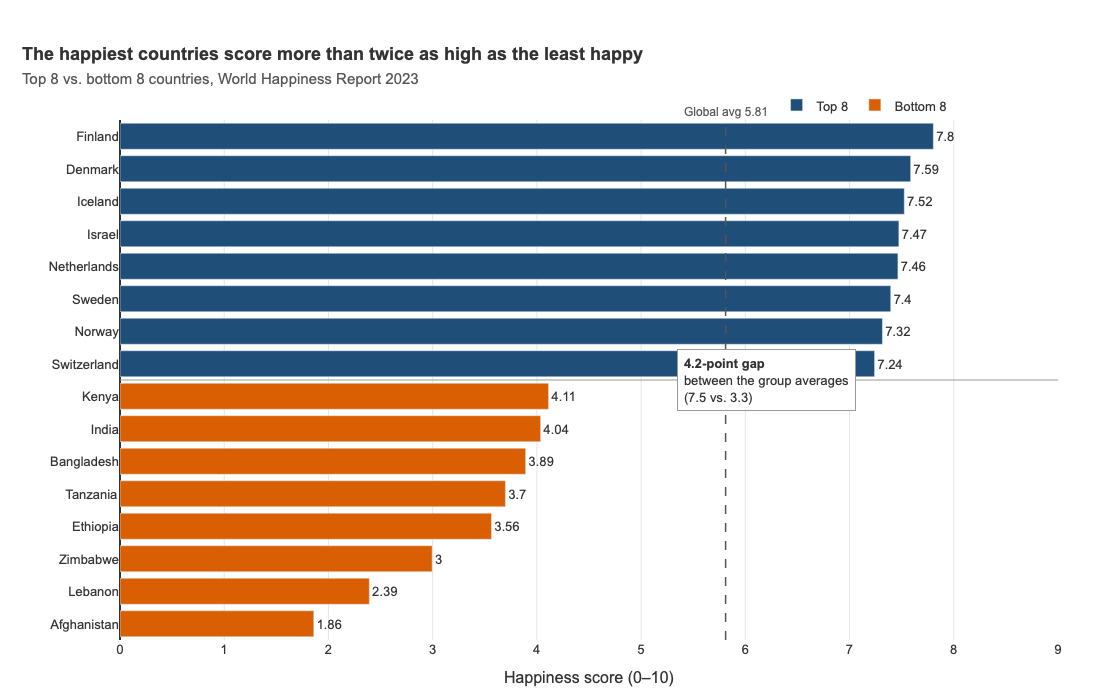

In [7]:
# Task 2: Top 8 vs. Bottom 8 contrast
# ------------------------------------

# Step 1: Get top and bottom countries
top8 = df.nlargest(8, 'Happiness_Score').copy()
top8['Group'] = 'Top 8'
bottom8 = df.nsmallest(8, 'Happiness_Score').copy()
bottom8['Group'] = 'Bottom 8'

combined = pd.concat([bottom8, top8]).sort_values('Happiness_Score')
global_avg = df['Happiness_Score'].mean()
print(f"Global average: {global_avg:.2f}")

# Step 2: Build your chart
# YOUR CODE HERE

# Step 2: Build your chart
color_map = {'Top 8': '#1f4e79', 'Bottom 8': '#d95f02'}
fig = go.Figure(go.Bar(
    x=combined['Happiness_Score'], y=combined['Country'], orientation='h',
    marker_color=combined['Group'].map(color_map),
    text=combined['Happiness_Score'].round(2), textposition='outside',
    cliponaxis=False, showlegend=False))

# Legend entries for the two groups (dummy traces)
for g, c in color_map.items():
    fig.add_trace(go.Bar(x=[None], y=[None], orientation='h', name=g, marker_color=c))

# Stretch goal: global average reference line
fig.add_vline(x=global_avg, line_dash='dash', line_color='#555', line_width=1.5)
fig.add_annotation(x=global_avg, y=1.0, yref='paper', yanchor='bottom',
                   text=f'Global avg {global_avg:.2f}', showarrow=False,
                   font=dict(size=12, color='#555'))

# Visual separator between the two groups (between bar 8 and 9)
fig.add_hline(y=7.5, line_color='#999', line_width=1)

# Annotation emphasising the gap
gap = top8['Happiness_Score'].mean() - bottom8['Happiness_Score'].mean()
fig.add_annotation(
    x=6.2, y=7.5, xref='x', yref='y', showarrow=False, align='left',
    text=f'<b>{gap:.1f}-point gap</b><br>between the group averages<br>'
         f'({top8["Happiness_Score"].mean():.1f} vs. {bottom8["Happiness_Score"].mean():.1f})',
    bgcolor='white', bordercolor='#999', borderwidth=1, borderpad=6,
    font=dict(size=13))

fig.update_layout(
    title=dict(text='<b>The happiest countries score more than twice as high as the least happy</b><br>'
                    '<span style="font-size:15px;color:#555">Top 8 vs. bottom 8 countries, '
                    'World Happiness Report 2023</span>',
               x=0.02, xanchor='left'),
    xaxis=dict(range=[0, 9], title='Happiness score (0–10)',
               gridcolor='#e6e6e6', zeroline=True, zerolinecolor='#333'),
    yaxis=dict(title=None),
    plot_bgcolor='white', paper_bgcolor='white',
    font=dict(family='Arial', size=13, color='#333'),
    legend=dict(orientation='h', yanchor='bottom', y=1.0, x=0.7),
    margin=dict(t=120, l=120, r=50, b=60),
    height=700, width=900)

fig.show()


---
## Done? Stretch Goal

If you finish both tasks with time to spare, try this:

**Task 3 (stretch):** Build a **grouped bar chart** comparing 2 sub-factors (e.g. `GDP_per_capita` and `Freedom`) across the 5 most populated regions. Use colour meaningfully and write an insight title.

Regions to include: `'Western Europe'`, `'Latin America'`, `'East Asia'`, `'Sub-Saharan Africa'`, `'South Asia'`


                             Social_Support  Freedom
Region                                              
Western Europe                        0.932    0.896
East Asia                             0.853    0.754
Latin America and Caribbean           0.829    0.754
South Asia                            0.561    0.546
Sub-Saharan Africa                    0.558    0.599


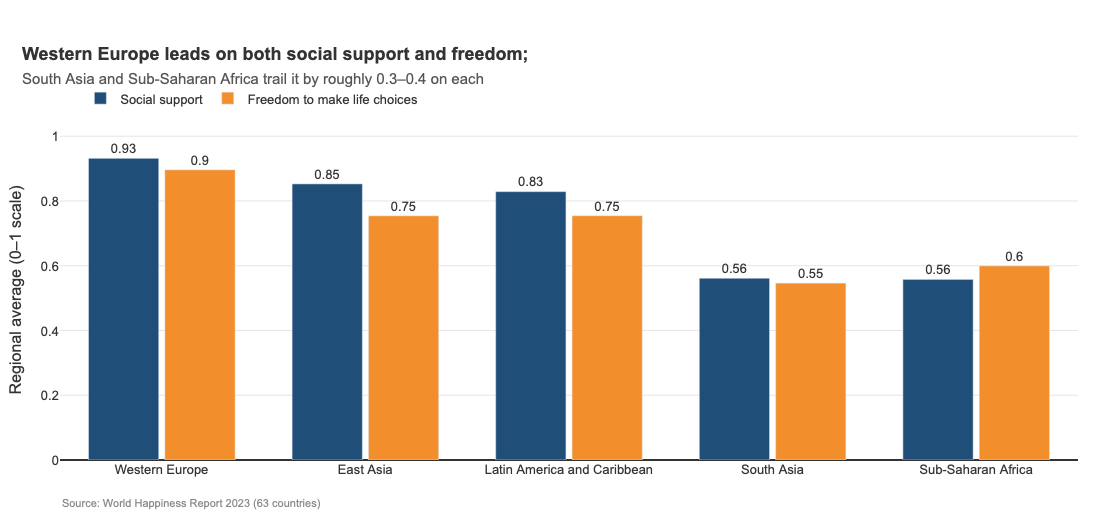

In [8]:
# Stretch goal — grouped bar chart
# YOUR CODE HERE

regions = ['Western Europe', 'Latin America and Caribbean', 'East Asia',
           'Sub-Saharan Africa', 'South Asia']

grp = (df[df['Region'].isin(regions)]
       .groupby('Region')[['Social_Support', 'Freedom']]
       .mean()
       .reindex(regions)                       # keep a deliberate order
       .sort_values('Social_Support', ascending=False))
print(grp.round(3))

fig = go.Figure()
fig.add_trace(go.Bar(
    name='Social support', x=grp.index, y=grp['Social_Support'],
    marker_color='#1f4e79', text=grp['Social_Support'].round(2),
    textposition='outside'))
fig.add_trace(go.Bar(
    name='Freedom to make life choices', x=grp.index, y=grp['Freedom'],
    marker_color='#f28e2b', text=grp['Freedom'].round(2),
    textposition='outside'))

fig.update_layout(
    barmode='group', bargap=0.25, bargroupgap=0.08,
    title=dict(text='<b>Western Europe leads on both social support and freedom;</b><br>'
                    '<span style="font-size:15px;color:#555">South Asia and Sub-Saharan Africa '
                    'trail it by roughly 0.3–0.4 on each</span>',
               x=0.02, xanchor='left'),
    yaxis=dict(range=[0, 1.05], title='Regional average (0–1 scale)',
               gridcolor='#e6e6e6', zeroline=True, zerolinecolor='#333'),
    xaxis=dict(title=None),
    plot_bgcolor='white', paper_bgcolor='white',
    font=dict(family='Arial', size=13, color='#333'),
    legend=dict(orientation='h', yanchor='bottom', y=1.02, x=0.02),
    margin=dict(t=120, l=60, r=30, b=60),
    height=520, width=900)

fig.add_annotation(
    text='Source: World Happiness Report 2023 (63 countries)',
    xref='paper', yref='paper', x=0, y=-0.15, showarrow=False,
    font=dict(size=11, color='#888'))

fig.show()
